# 03 — Image Preprocessing

Both a demonstration of the OpenCV pipeline and the evidence for which operations
are justified. Numerical results come from `src/preprocessing/evaluate.py`, which
measures 190 training images across nine operations.


In [1]:
import sys, json, warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the project root by walking upward until config.py is found.  This is
# robust to the kernel's working directory being either the project root or the
# notebooks/ directory, which differs between nbconvert, JupyterLab and VS Code.
_here = Path.cwd().resolve()
ROOT = _here
for _cand in (_here, *_here.parents):
    if (_cand / "config.py").exists():
        ROOT = _cand
        break
else:
    raise RuntimeError(f"could not locate project root from {_here}")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib
import config

GRAPHS = "evaluation/graphs"
from IPython.display import Image, display, Markdown
from src.utils import load_json, fmt_bytes, imread_unicode

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
print("kernel cwd :", _here)
print("project root:", ROOT)
print("python      :", sys.version.split()[0])


kernel cwd : C:\Users\Sachin\OneDrive\Documents\Skanda's IPCV proj\Notebooks
project root: C:\Users\Sachin\OneDrive\Documents\Skanda's IPCV proj
python      : 3.12.16


In [2]:
from src.preprocessing.pipeline import (
    PRESETS, get_preset, preprocess_with_stages, display_stages,
    image_quality_metrics, segment_vegetable, bgr_to_rgb, resize,
)
from src.preprocessing.augment import augment, augmentation_grid, AugmentConfig
from src.visualize import plot_before_after, plot_augmentation_grid

study = load_json(config.EVAL_REPORT_DIR / "preprocessing_study.json")
agg = pd.DataFrame(study["aggregate"]).set_index("operation")
inventory = pd.read_csv(config.METADATA_DIR / "image_inventory.csv")
sample = inventory[inventory["quality"] == "Ripe"].iloc[0]
raw_bgr = imread_unicode(config.RAW_DIR / sample["rel_path"])
print("example image:", sample["vegetable"], "/", sample["quality"], sample["file_name"])

example image: Bell Pepper / Ripe IMG_20220530_085141.jpg


## 1. What each operation actually does

In [3]:
display(agg[["noise_sigma", "noise_reduction_pct", "sharpness_retained_pct",
             "contrast_change_pct", "ssim_to_raw", "time_ms"]].round(3))

display(Markdown(
    "- **Noise** is a Laplacian-MAD estimate; lower is smoother.\n"
    "- **Sharpness kept** compares Laplacian variance to the unprocessed image.\n"
    "- **SSIM vs raw** shows how much the operation changes the image at all."
))

,noise_sigma,noise_reduction_pct,sharpness_retained_pct,contrast_change_pct,ssim_to_raw,time_ms
operation,,,,,,
identity,0.949,0.000,100.000,0.000,1.000,0.002
gaussian_3,0.723,23.826,24.387,-0.884,0.990,0.189
gaussian_5,0.672,29.195,13.337,-1.447,0.980,0.219
median_3,0.819,13.758,61.200,-0.330,0.990,0.097
median_5,0.685,27.852,42.568,-0.875,0.972,0.377
bilateral,0.656,30.872,94.385,-0.329,0.989,0.524
clahe,2.472,-160.403,259.016,8.606,0.895,0.940
median3+clahe,2.160,-127.517,142.689,8.478,0.903,0.956
gaussian3+clahe,2.058,-116.778,72.282,8.650,0.901,1.073


- **Noise** is a Laplacian-MAD estimate; lower is smoother.
- **Sharpness kept** compares Laplacian variance to the unprocessed image.
- **SSIM vs raw** shows how much the operation changes the image at all.

The measured result is not the textbook default:

* **Bilateral filtering dominates.** It removes 31% of the high-frequency noise
  while retaining 94% of the sharpness measure, at 0.5 ms per image. Gaussian
  blur removes a comparable amount but destroys 76% of the detail.
* **Gaussian blur is the worst choice here** at any kernel size — it is a linear
  low-pass filter and this dataset's artefacts are impulse-like JPEG blocks.
* **CLAHE increases** the Laplacian measure by 160%. That is partly genuine
  local-contrast enhancement and partly amplified noise; the metric cannot tell
  them apart, so CLAHE's value must be settled by validation macro F1, not by
  appearance.


## 2. Before / after

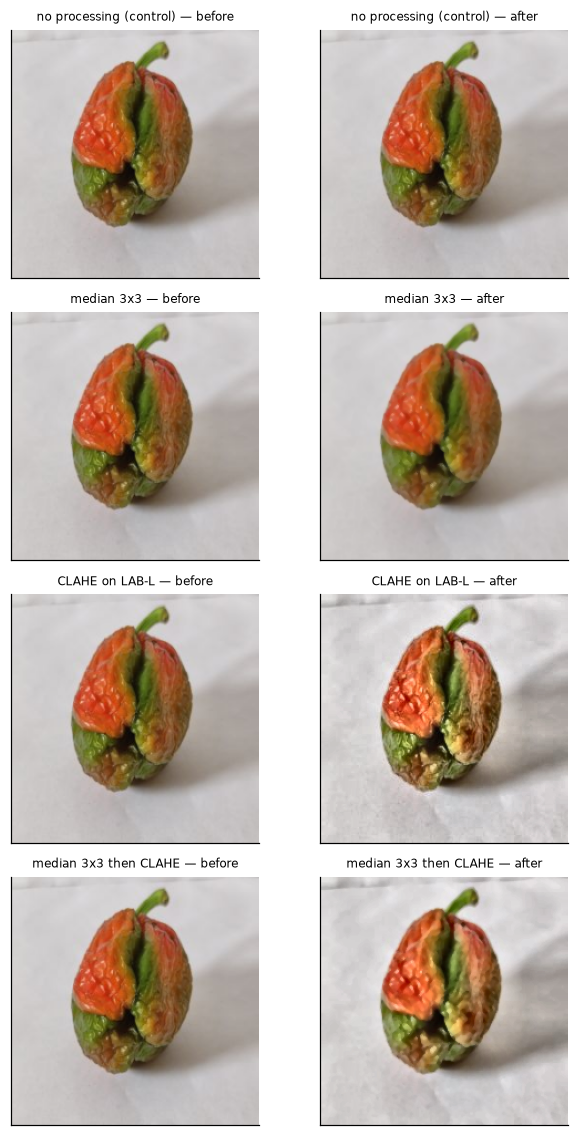

In [4]:
display(Image(filename=str(ROOT / f"{GRAPHS}/preprocessing_before_after.png")))

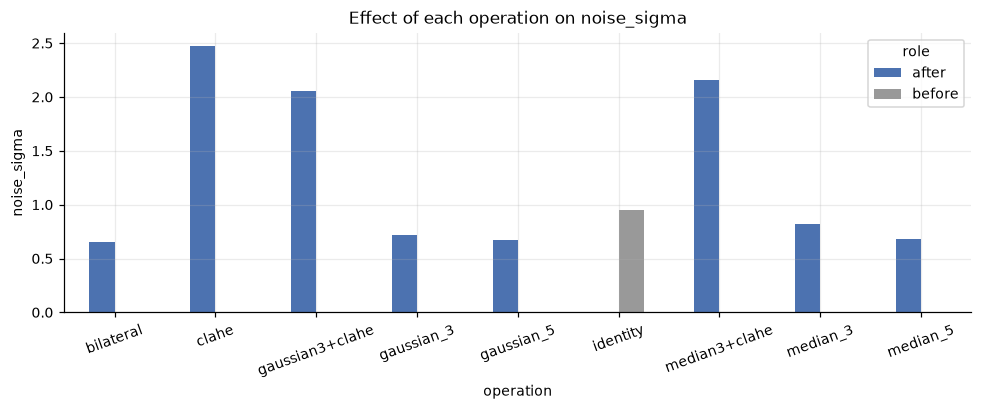

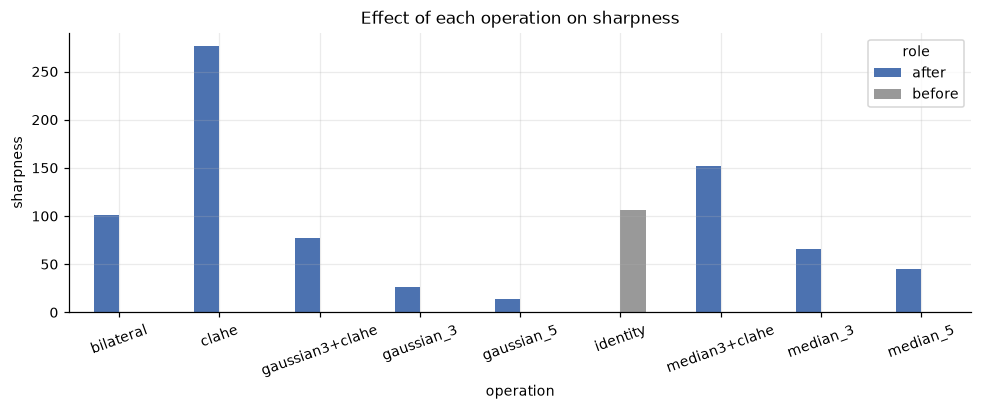

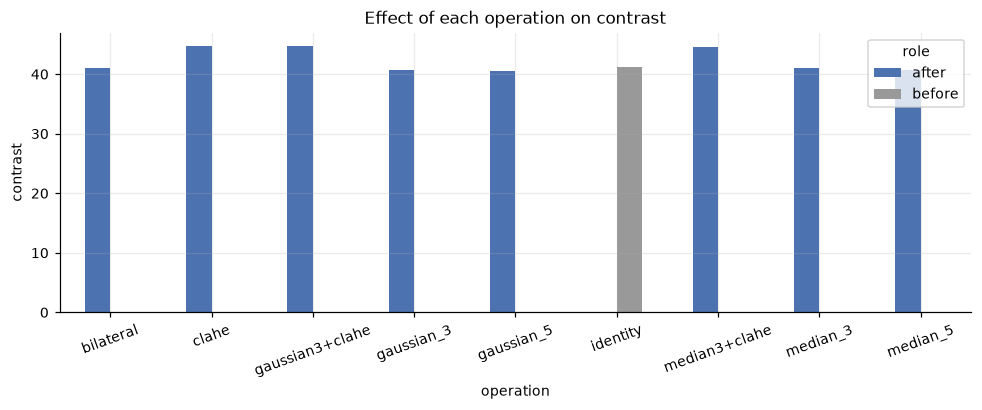

In [5]:
for metric in ("noise_sigma", "sharpness", "contrast"):
    display(Image(filename=str(ROOT / f"{GRAPHS}/preprocessing_{metric}.png")))

## 3. The pipeline presets

In [6]:
display(pd.DataFrame([{"preset": k, **v.describe()} for k, v in PRESETS.items()]))

,preset,size,resize_mode,denoise,denoise_ksize,clahe,clahe_clip,clahe_tiles,segment,normalize
0,basic,224,squash,NaN,3,False,2.0,"[8, 8]",False,imagenet
1,enhanced,224,squash,median,3,True,2.0,"[8, 8]",False,imagenet
2,bilateral,224,squash,bilateral,3,True,2.0,"[8, 8]",False,imagenet
3,segmented,224,squash,median,3,True,2.0,"[8, 8]",True,imagenet


Each preset is a named, serialisable configuration — the same config is stored
with the trained model, so serving cannot drift from training.


## 4. Stage-by-stage visualisation

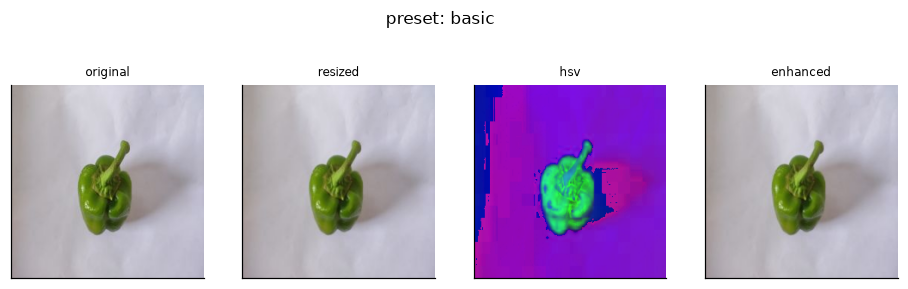

`basic`: original → resized → hsv → enhanced

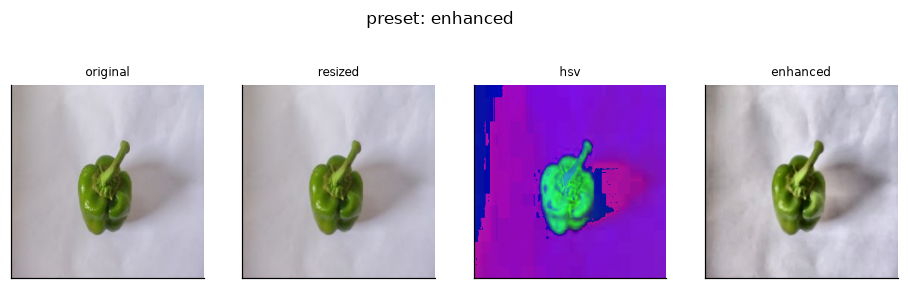

`enhanced`: original → resized → hsv → enhanced

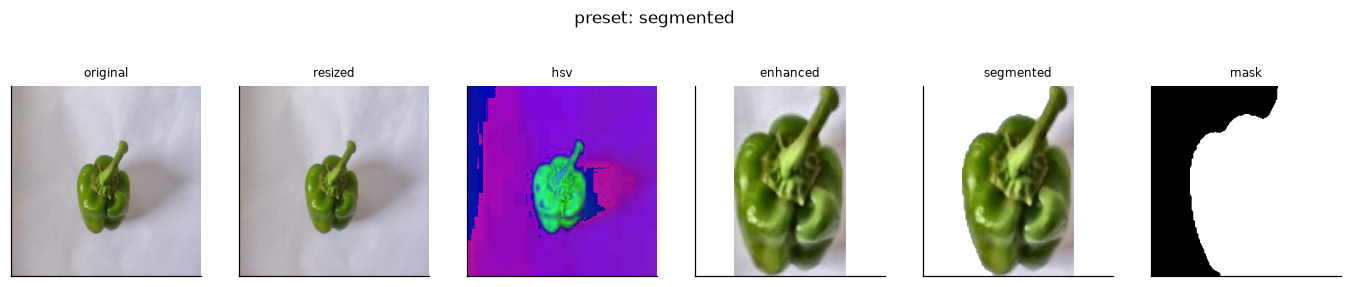

`segmented`: original → resized → hsv → enhanced → segmented → mask

In [7]:
for preset in ("basic", "enhanced", "segmented"):
    _, info = preprocess_with_stages(raw_bgr, get_preset(preset))
    stages = display_stages(info["stages"])
    labels = " → ".join(name for name, _ in stages)
    panel = [img for _, img in stages]
    n = len(panel)
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, n, figsize=(2.6 * n, 2.9))
    for ax, (name, img) in zip(np.atleast_1d(axes), stages):
        ax.imshow(img if img.ndim == 3 else img, cmap=None if img.ndim == 3 else "gray")
        ax.set_title(name, fontsize=8); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    fig.suptitle(f"preset: {preset}", y=1.03)
    out = ROOT / f"{GRAPHS}/pipeline_stages_{preset}.png"
    fig.savefig(out, bbox_inches="tight", dpi=110)
    plt.close(fig)
    display(Image(filename=str(out)))
    display(Markdown(f"`{preset}`: {labels}"))

## 5. Segmentation behaviour

,images sampled,usable masks,mean foreground fraction,5th percentile,95th percentile,failures by class
0,190,99.5%,0.249,0.048,0.55,{'Dried': 1}


area fraction: 0.094 | ok: True


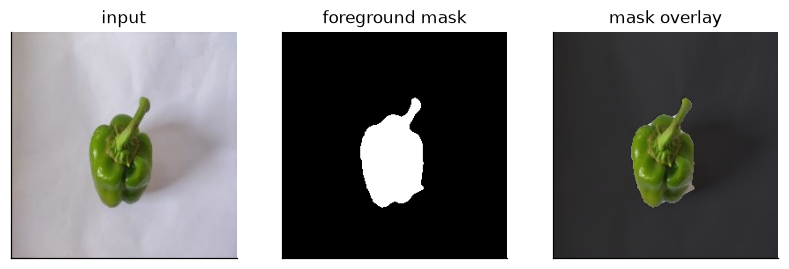

In [8]:
seg = study["segmentation"]
display(pd.DataFrame([{
    "images sampled": seg["n"],
    "usable masks": f"{seg['usable_fraction']*100:.1f}%",
    "mean foreground fraction": round(seg["area_fraction_mean"], 3),
    "5th percentile": round(seg["area_fraction_p05"], 3),
    "95th percentile": round(seg["area_fraction_p95"], 3),
    "failures by class": str(seg["failures_by_quality"]),
}]))

mask, info = segment_vegetable(raw_bgr)
print("area fraction:", round(info["area_fraction"], 3), "| ok:", info["ok"])

import matplotlib.pyplot as plt
rgb = bgr_to_rgb(raw_bgr)
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
axes[0].imshow(rgb); axes[0].set_title("input")
axes[1].imshow(mask, cmap="gray"); axes[1].set_title("foreground mask")
overlay = rgb.copy(); overlay[mask == 0] = (overlay[mask == 0] * 0.25).astype(np.uint8)
axes[2].imshow(overlay); axes[2].set_title("mask overlay")
for ax in axes: ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
out = ROOT / f"{GRAPHS}/segmentation_example.png"
fig.savefig(out, bbox_inches="tight", dpi=110); plt.close(fig)
display(Image(filename=str(out)))

## 6. Augmentation

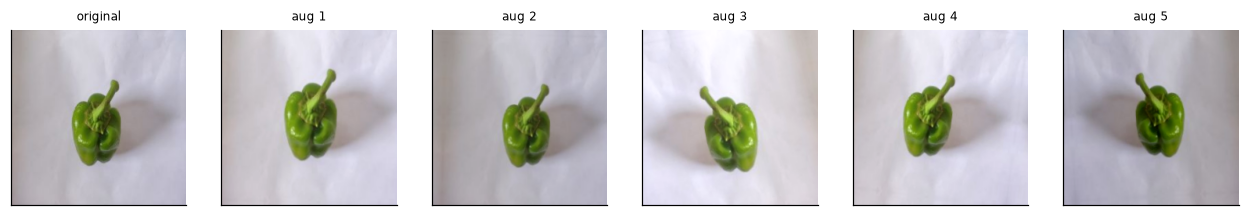

config: {'rotation_deg': 12.0, 'zoom': 0.1, 'translate_frac': 0.06, 'brightness_delta': 0.12, 'contrast_delta': 0.12, 'hflip_p': 0.5, 'apply_p': 0.9}


In [9]:
base = resize(bgr_to_rgb(raw_bgr), config.IMAGE_SIZE, "squash")
grid = augmentation_grid(base, n=5, seed=config.SEED)
fig, axes = plt.subplots(1, len(grid), figsize=(2.4 * len(grid), 2.7))
for ax, img, label in zip(np.atleast_1d(axes), grid,
                          ["original"] + [f"aug {i}" for i in range(1, len(grid))]):
    ax.imshow(img); ax.set_title(label, fontsize=8)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
out = ROOT / f"{GRAPHS}/augmentation_examples.png"
fig.savefig(out, bbox_inches="tight", dpi=110); plt.close(fig)
display(Image(filename=str(out)))

print("config:", AugmentConfig().describe())

Augmentation is applied **only to the training split, only inside the training
pipeline**, never to validation or test, and never before splitting. The
transform is implemented in `src/preprocessing/augment.py` with a single affine
warp (rotation + zoom + translation composed into one matrix) so the image is
resampled once rather than three times.

Horizontal flip is allowed; vertical flip is not, because vegetables have a
canonical upright orientation. Hue rotation is deliberately excluded: ripeness
in this dataset is largely a hue cue, and shifting hue would effectively relabel
the image.


## 7. Do handcrafted features carry signal?

In [10]:
fs = load_json(config.EVAL_REPORT_DIR / "feature_screening.json")
display(pd.DataFrame({
    "scheme": ["grouped CV (honest)", "random CV (optimistic)"],
    **{
        name: [round(fs["group_benchmark_macro_f1_grouped_cv"][name]["macro_f1_mean"], 4),
               round(fs["group_benchmark_macro_f1_random_cv"][name]["macro_f1_mean"], 4)]
        for name in fs["group_benchmark_macro_f1_grouped_cv"]
    },
}).rename(columns={"all": "all features", "colour": "colour only",
                   "texture": "texture only", "shape": "shape only"}))

print(f"near-duplicate inflation when the group structure is ignored: "
      f"{fs['near_duplicate_inflation_all_features']:+.4f} macro-F1")
print("features screened:", fs["n_features"], "images:", fs["n_images"],
      "duplicate-safe groups:", fs["n_groups"])

,scheme,colour only,texture only,shape only,all features
0,grouped CV (honest),0.8966,0.6991,0.4062,0.9199
1,random CV (optimistic),0.9315,0.7527,0.5068,0.9446


near-duplicate inflation when the group structure is ignored: +0.0248 macro-F1
features screened: 83 images: 4286 duplicate-safe groups: 2709


,feature,group,anova_f,p_value,mutual_info,rf_importance
0,glcm_homogeneity_d1,texture,244.4163,0.0,0.1757,0.0515
1,glcm_contrast_d3,texture,233.5981,0.0,0.2269,0.0433
2,lbp16_7,texture,452.1988,0.0,0.2215,0.0347
3,hue_hist_2,colour,347.4494,0.0,0.2414,0.0276
4,lbp16_15,texture,484.1040,0.0,0.2259,0.0264
5,sat_mean,colour,85.6003,0.0,0.1185,0.0258
6,lbp16_10,texture,362.9377,0.0,0.2272,0.0253
7,hue_hist_0,colour,61.6804,0.0,0.1262,0.0251
8,glcm_contrast_d1,texture,254.7439,0.0,0.2274,0.0221
9,lbp16_9,texture,601.5442,0.0,0.2486,0.0215


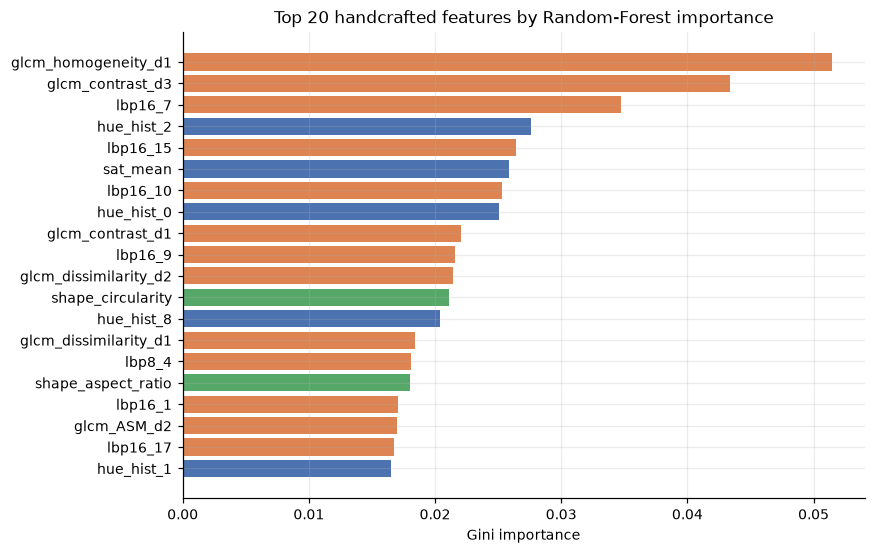

In [11]:
import matplotlib.pyplot as plt
from src.features.handcrafted import ALL_FEATURES

screen = pd.read_csv(config.METRICS_DIR / "feature_screening.csv")
display(screen.head(12).round(4))

top = screen.nlargest(20, "rf_importance").iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
colours = {"colour": "#4c72b0", "texture": "#dd8452", "shape": "#55a868"}
ax.barh(top["feature"], top["rf_importance"],
        color=[colours.get(g, "#999") for g in top["group"]])
ax.set_title("Top 20 handcrafted features by Random-Forest importance")
ax.set_xlabel("Gini importance")
out = ROOT / f"{GRAPHS}/feature_importance_top20.png"
fig.savefig(out, bbox_inches="tight", dpi=110); plt.close(fig)
display(Image(filename=str(out)))

This is the most consequential Phase 1 result.

Colour descriptors alone reach **0.897 macro-F1** on quality classification
under grouped cross-validation; all 83 descriptors reach **0.920**. That sets the
bar the deep models must clear in Phase 2. If a CNN lands below this, the honest
conclusion is that the extra capacity is not buying anything on this corpus — not
that the CNN "works".

The gap between grouped and random CV is the measured cost of ignoring duplicate
clusters. It is roughly 2.5 macro-F1 points, which is the size of the leakage
error this project's split design exists to avoid.

Shape features are the weakest group (0.406) as expected: this dataset is a
*condition* classification problem, not a shape problem.
